# Dual-RX gain/frequency phase calibration: model ladder

This notebook is the decision-oriented index over **all committed artifacts** in this report directory. It inventories every report, loads every model-matrix JSON, compares only like-for-like validation masks, and proposes the next low-parameter models to train.

## Decision in one paragraph

For a previously calibrated Pluto at an exact LO, use the serial-specific, per-frequency antisymmetric model $C_{r,f}+H_{r,f}(g_1)-H_{r,f}(g_2)$ as the parsimonious precision default. On the 53-frequency integer-gain survey it uses 6,784 fleet coefficients (3,392/radio), reaches 0.912° leave-one-epoch-out MAE and 1.074° genuinely held-out off-axis MAE, and saves about half the coefficients of independent RX1/RX2 curves. If roughly 2.5° MAE is acceptable, the gain-table-specific frequency-scaled model is the compact tested choice: 484 fleet coefficients (242/radio). A full gain-pair table, a global linear gain model, and a delay-only frequency model are rejected by held-out results. Exact-frequency and per-session anchors remain necessary.

> **Evidence boundary.** The committed JSON files contain trained coefficients and held-out metrics, but the large V7 IQ stores live under gitignored `artifacts/` and are not in this checkout. The default run therefore audits and re-analyzes the frozen trained outputs. The final cell provides an opt-in raw-data refit when those stores are mounted.

In [1]:
from __future__ import annotations

import hashlib
import json
import re
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option('display.max_colwidth', 90)
plt.style.use('seaborn-v0_8-whitegrid')

def find_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'spf/calibrations/dual_rx_gain_frequency/reports').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate the SPF repository root')

REPO = find_repo_root()
REPORTS = REPO / 'spf/calibrations/dual_rx_gain_frequency/reports'
print(f'Repository: {REPO}')
print(f'Reports:    {REPORTS}')

Repository: /home/mouse9911/gits/spf
Reports:    /home/mouse9911/gits/spf/spf/calibrations/dual_rx_gain_frequency/reports


## 1. Immutable report inventory

The inventory makes the notebook self-checking as reports are added. JSON and CSV hold the machine-readable fits and metrics; Markdown records experimental scope and caveats; PNG files are generated views of the same analyses.

In [2]:
artifact_paths = sorted(p for p in REPORTS.rglob('*') if p.is_file() and p.name != 'MODEL_LADDER_ANALYSIS.ipynb')
inventory = pd.DataFrame([
    {
        'path': p.relative_to(REPORTS).as_posix(),
        'type': p.suffix.lower() or '<none>',
        'bytes': p.stat().st_size,
        'sha256_12': hashlib.sha256(p.read_bytes()).hexdigest()[:12],
    }
    for p in artifact_paths
])
summary = (inventory.groupby('type', as_index=False)
           .agg(files=('path', 'size'), bytes=('bytes', 'sum'))
           .sort_values('files', ascending=False))
display(summary)

markdown_catalog = inventory[inventory.type == '.md'][['path', 'bytes', 'sha256_12']].reset_index(drop=True)
display(Markdown(f'**{len(inventory)} files indexed; {len(markdown_catalog)} narrative reports reviewed.**'))
display(markdown_catalog)

,type,files,bytes
4,.png,194,42557181
3,.md,28,282780
1,.json,21,8620399
0,.csv,4,10390
2,.jsonl,2,33599


**249 files indexed; 28 narrative reports reviewed.**

,path,bytes,sha256_12
0,ALL_GAIN_CROSS_2P4_20260729.md,7035,6f547d7f7271
1,EXTERNAL_WALL_VALIDATION_2467P1_20260729.md,7524,ac30098a6181
2,FREQUENCY_SCOUT_20260727.md,11093,a1d45bcf85e5
3,HISTORICAL_EXACT_LO_CROSS_2P4_20260729.md,6350,d25946255877
4,INTEGER_GAIN_CROSS_2P4_20260729.md,8539,cb29f0d8272d
5,README.md,11659,ae3e85afb207
6,coarse_5ghz_20260727_dds_v1/REPORT.md,12980,ba18c02e6851
7,four_radio_dense_20260728_v1/LOW_COST_CALIBRATION_REPORT.md,6580,19a96954d65e
8,four_radio_dense_20260728_v1/MODEL_MATRIX_REPORT.md,7672,eff2f7f71a09
9,four_radio_dense_20260728_v1/PER_FREQUENCY_ADDITIVE_GAIN_LUT.md,13699,02020a27468a


## 2. Load the trained model matrices

The three evaluation regimes answer different questions and must not be blended:

- **LOEO — leave one epoch out:** repeatability at already measured radio/frequency/gain cells.
- **LOFO — leave one frequency out:** prediction at an unmeasured LO. Exact-frequency LUTs are unsupported by design.
- **LORO — leave one radio out:** transfer to a physically unseen Pluto. Radio-specific models are unsupported by design.

The separate additive-cross test is stronger than LOEO for gain shape: it fits only the RX1/RX2 axes and scores gain pairs deliberately excluded from training.

In [3]:
matrix_paths = sorted(REPORTS.glob('*/model_matrix.json'))
matrices = {p.parent.name: json.loads(p.read_text()) for p in matrix_paths}

def metric(model: dict, split: str, field: str):
    return (model.get(split) or {}).get(field)

rows = []
study_rows = []
for study, doc in matrices.items():
    provenance = doc.get('provenance', [])
    study_rows.append({
        'study': study,
        'radios': len(provenance),
        'frequencies': len(doc.get('frequencies_hz', [])),
        'gains': len(doc.get('gains_db', [])),
        'completed_frames': sum(x.get('completed_frames', 0) for x in provenance),
        'quality_valid': sum(x.get('quality_valid_observations', 0) for x in provenance),
        'models': len(doc.get('models', {})),
    })
    for model_id, model in doc.get('models', {}).items():
        fits = model.get('fits', [])
        parameters = sum(int(f.get('parameter_count', 0)) for f in fits)
        rows.append({
            'study': study,
            'n_radios': len(provenance),
            'model_id': model_id,
            'label': model.get('label', model_id),
            'scope': model.get('scope'),
            'formula': model.get('formula'),
            'parameters': parameters,
            'parameters_per_radio': parameters / len(provenance) if model.get('scope') == 'per_radio' and provenance else np.nan,
            'loeo_mae_deg': metric(model, 'leave_one_epoch_out', 'circular_mae_deg'),
            'loeo_p95_deg': metric(model, 'leave_one_epoch_out', 'circular_p95_deg'),
            'loeo_coverage': metric(model, 'leave_one_epoch_out', 'coverage_fraction'),
            'lofo_mae_deg': metric(model, 'leave_one_frequency_out', 'circular_mae_deg'),
            'loro_mae_deg': metric(model, 'leave_one_radio_out', 'circular_mae_deg'),
        })

study_df = pd.DataFrame(study_rows).sort_values(['frequencies', 'radios'])
matrix_df = pd.DataFrame(rows)
display(study_df.reset_index(drop=True))
assert len(matrices) == 4, 'A model-matrix report was added or removed; review the notebook synthesis.'
assert matrix_df.loeo_coverage.dropna().ge(0.999).all(), 'A compared model has materially incomplete LOEO coverage.'

,study,radios,frequencies,gains,completed_frames,quality_valid,models
0,survey_cross_band_20260727_v1,2,12,17,20808,20409,13
1,four_radio_dense_20260728_v1,4,12,17,41616,40510,13
2,six_radio_dense_20260729_v1,6,12,17,62424,60875,13
3,wide_integer_gain_cross_band_20260730_v1,2,53,64,55650,55602,18


### Dense-grid replication across 2, 4, and 6 radios

These three studies share the same 12-frequency, 17-gain design. The radio-specific exact-frequency additive model stays near 0.9° as radios are added. Universal transfer degrades sharply because board-specific frequency baselines are real; adding radios does not make a serial-free correction precise.

,n_radios,label,scope,parameters,loeo_mae_deg,loeo_p95_deg,loro_mae_deg
0,2,Per-frequency additive gain LUT per radio,per_radio,792,0.874,3.053,NaN
1,2,Full frequency/gain-pair LUT per radio,per_radio,6936,0.912,3.318,NaN
2,2,Strict universal per-frequency additive LUT,universal,396,5.303,16.274,10.507
3,2,Gain-dependent branch-delay LUT per radio,per_radio,132,9.212,24.872,NaN
4,4,Per-frequency additive gain LUT per radio,per_radio,1584,0.903,3.069,NaN
5,4,Full frequency/gain-pair LUT per radio,per_radio,13872,0.949,3.273,NaN
6,4,Gain-dependent branch-delay LUT per radio,per_radio,264,9.367,27.798,NaN
7,4,Strict universal per-frequency additive LUT,universal,396,10.677,38.997,14.171
8,6,Per-frequency additive gain LUT per radio,per_radio,2376,0.904,3.083,NaN
9,6,Full frequency/gain-pair LUT per radio,per_radio,20808,0.956,3.296,NaN


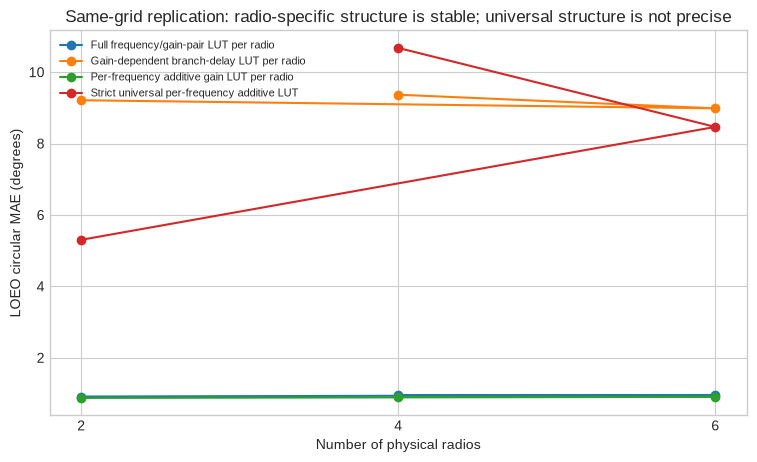

In [4]:
dense_studies = [
    'survey_cross_band_20260727_v1',
    'four_radio_dense_20260728_v1',
    'six_radio_dense_20260729_v1',
]
replication_models = [
    'frequency_specific_additive_gain_per_radio',
    'full_cell_lut_per_radio',
    'branch_gain_delay_lut_per_radio',
    'frequency_specific_additive_gain_universal',
]
replication = matrix_df[
    matrix_df.study.isin(dense_studies) & matrix_df.model_id.isin(replication_models)
].copy()
display(replication[['n_radios', 'label', 'scope', 'parameters', 'loeo_mae_deg', 'loeo_p95_deg', 'loro_mae_deg']]
        .sort_values(['n_radios', 'loeo_mae_deg']).round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 5))
for label, group in replication.groupby('label'):
    ax.plot(group.n_radios, group.loeo_mae_deg, marker='o', label=label)
ax.set(xlabel='Number of physical radios', ylabel='LOEO circular MAE (degrees)', xticks=[2, 4, 6])
ax.legend(fontsize=8, loc='upper left')
ax.set_title('Same-grid replication: radio-specific structure is stable; universal structure is not precise')
plt.show()

## 3. Wide-survey parameter/error frontier

This is the best cross-band dataset for model selection: two Pluto Plus units, 53 exact LOs from 433 MHz to 5.9 GHz, gains −1…62 dB, three randomized epochs, and 48 off-axis held-out gain pairs per frequency. Parameter counts below are **fleet totals for two radios**, not per-radio counts.

,label,parameters,parameters_per_radio,loeo_mae_deg,loeo_p95_deg
0,Constant per radio,2,1.0,14.810,49.754
1,Linear gains per radio,6,3.0,14.779,49.051
2,Frequency LUT + linear gains per radio,110,55.0,6.268,16.239
3,Frequency LUT + f-scaled symmetric gain LUT per radio,232,116.0,4.517,11.923
4,Frequency LUT + gain-table-specific f-scaled symmetric gain LUT per radio,484,242.0,2.665,10.368
5,Per-frequency antisymmetric gain LUT per radio,6784,3392.0,0.912,2.963
6,Per-frequency additive gain LUT per radio,13462,6731.0,0.713,2.528


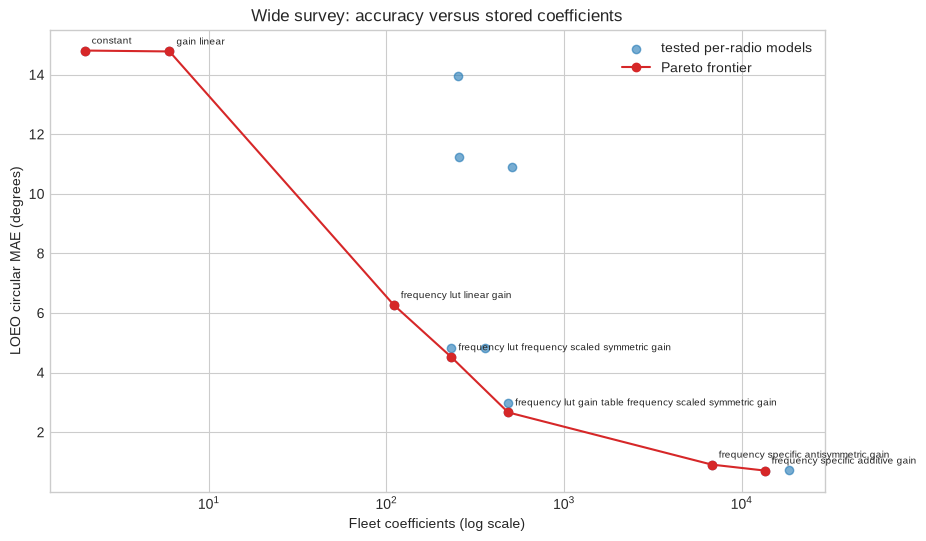

In [5]:
WIDE = 'wide_integer_gain_cross_band_20260730_v1'
wide = matrix_df[matrix_df.study == WIDE].copy()
wide_per_radio = wide[(wide.scope == 'per_radio') & wide.loeo_mae_deg.notna()].sort_values('parameters')

def pareto_front(df: pd.DataFrame, x: str, y: str) -> pd.DataFrame:
    best = np.inf
    keep = []
    for idx, row in df.sort_values([x, y]).iterrows():
        if row[y] < best:
            keep.append(idx)
            best = row[y]
    return df.loc[keep].sort_values(x)

frontier = pareto_front(wide_per_radio, 'parameters', 'loeo_mae_deg')
display(frontier[['label', 'parameters', 'parameters_per_radio', 'loeo_mae_deg', 'loeo_p95_deg']]
        .round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(wide_per_radio.parameters, wide_per_radio.loeo_mae_deg, alpha=.6, label='tested per-radio models')
ax.plot(frontier.parameters, frontier.loeo_mae_deg, '-o', color='tab:red', label='Pareto frontier')
for _, row in frontier.iterrows():
    ax.annotate(row.model_id.replace('_per_radio', '').replace('_', ' '),
                (row.parameters, row.loeo_mae_deg), xytext=(5, 5), textcoords='offset points', fontsize=7)
ax.set_xscale('log')
ax.set(xlabel='Fleet coefficients (log scale)', ylabel='LOEO circular MAE (degrees)',
       title='Wide survey: accuracy versus stored coefficients')
ax.legend()
plt.show()

### Do not let an exact-frequency LUT answer an unseen-frequency question

Blank cells mean structurally unsupported, not zero error. Delay terms are physically interpretable as *effective differential group delay*, but the 11.43° best LOFO MAE rejects cable/trace delay as the only cross-frequency mechanism. Pluto retunes, analogue dispersion, and the three frequency-dependent AD936x gain tables remain important.

In [6]:
regime_ids = [
    'constant_per_radio',
    'frequency_lut_gain_table_frequency_scaled_symmetric_gain_per_radio',
    'frequency_specific_antisymmetric_gain_per_radio',
    'frequency_specific_additive_gain_per_radio',
    'branch_gain_delay_lut_per_radio',
    'frequency_specific_additive_gain_universal',
    'branch_gain_delay_lut_universal',
]
regimes = wide[wide.model_id.isin(regime_ids)][
    ['label', 'scope', 'parameters', 'loeo_mae_deg', 'loeo_p95_deg', 'lofo_mae_deg', 'loro_mae_deg']
].sort_values('loeo_mae_deg')
display(regimes.round(3).reset_index(drop=True))

,label,scope,parameters,loeo_mae_deg,loeo_p95_deg,lofo_mae_deg,loro_mae_deg
0,Per-frequency additive gain LUT per radio,per_radio,13462,0.713,2.528,NaN,NaN
1,Per-frequency antisymmetric gain LUT per radio,per_radio,6784,0.912,2.963,NaN,NaN
2,Frequency LUT + gain-table-specific f-scaled symmetric gain LUT per radio,per_radio,484,2.665,10.368,NaN,NaN
3,Strict universal per-frequency additive LUT,universal,6731,3.239,16.051,NaN,6.213
4,Gain-dependent branch-delay LUT per radio,per_radio,508,10.899,37.160,11.430,NaN
5,Strict universal gain-dependent delay LUT,universal,254,11.023,34.978,11.526,11.681
6,Constant per radio,per_radio,2,14.810,49.754,15.029,NaN


## 4. Genuine off-axis gain-pair holdout

This is the decisive comparison for interpolation over the gain plane. Each model trains on the additive cross (one receiver swept while the other is fixed at the reference gain) and predicts 15,216 quality-valid observations from 48 gain pairs per frequency that were never used for fitting.

,label,parameters,mae_deg,p95_deg,max_deg,coverage
0,Per-frequency additive gain LUT per radio,13462,0.805,2.699,11.430,1.0
1,Per-frequency antisymmetric gain LUT per radio,6784,1.074,3.485,16.329,1.0
2,Frequency LUT + gain-table-specific f-scaled symmetric gain LUT per radio,484,2.496,8.744,22.548,1.0
3,Frequency LUT + gain-table-specific symmetric gain LUT per radio,484,2.743,9.656,22.100,1.0
4,Frequency LUT + f-scaled symmetric gain LUT per radio,232,4.551,12.931,27.159,1.0
5,Frequency LUT + symmetric gain LUT per radio,232,4.995,14.830,25.504,1.0


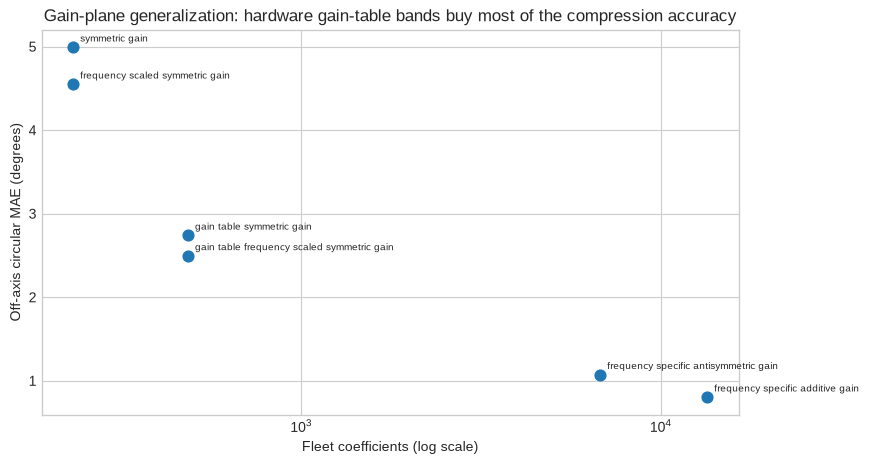

**Compact tested choice:** 2.496° MAE with 484 fleet coefficients. **Accuracy reference:** 0.805° MAE with 13462 coefficients. The compact model removes 96.4% of the coefficients.

In [7]:
wide_doc = matrices[WIDE]
held_out = wide_doc['held_out_gain_pair_comparison']
off_axis_rows = []
for model_id, values in held_out['models'].items():
    off_axis_rows.append({
        'model_id': model_id,
        'label': values['label'],
        'parameters': values['parameter_count'],
        'mae_deg': values['circular_mae_deg'],
        'p95_deg': values['circular_p95_deg'],
        'max_deg': values['circular_max_deg'],
        'coverage': values['coverage_fraction'],
    })
off_axis = pd.DataFrame(off_axis_rows).sort_values('mae_deg')
display(off_axis[['label', 'parameters', 'mae_deg', 'p95_deg', 'max_deg', 'coverage']].round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(off_axis.parameters, off_axis.mae_deg, s=60)
for _, row in off_axis.iterrows():
    ax.annotate(row.model_id.replace('frequency_lut_', '').replace('_per_radio', '').replace('_', ' '),
                (row.parameters, row.mae_deg), xytext=(5, 4), textcoords='offset points', fontsize=7)
ax.set_xscale('log')
ax.set(xlabel='Fleet coefficients (log scale)', ylabel='Off-axis circular MAE (degrees)',
       title='Gain-plane generalization: hardware gain-table bands buy most of the compression accuracy')
plt.show()

compact = off_axis.set_index('model_id').loc['frequency_lut_gain_table_frequency_scaled_symmetric_gain_per_radio']
reference = off_axis.set_index('model_id').loc['frequency_specific_additive_gain_per_radio']
display(Markdown(
    f"**Compact tested choice:** {compact.mae_deg:.3f}° MAE with {int(compact.parameters)} fleet coefficients. "
    f"**Accuracy reference:** {reference.mae_deg:.3f}° MAE with {int(reference.parameters)} coefficients. "
    f"The compact model removes {100 * (1 - compact.parameters / reference.parameters):.1f}% of the coefficients."
))

## 5. Independent evidence for hardware-stage structure

The preliminary 5.8 GHz analysis used deterministic held-out gain-pair folds. Its stage boundaries came from the AD9361 driver gain-table plateaus (`−6, 6, 16, 23, 26, 41 dB`) plus a high-gain ramp. The result is narrow-band and exploratory, but it is unusually strong evidence for the next compact model family.

,label,parameters_per_radio_frequency,mean_mae_deg,worst_mae_deg,mean_p95_deg
0,Constant baseline,1,9.782,10.668,24.817
1,Linear gain difference,2,9.846,10.710,22.673
2,Separate linear RX1/RX2,3,9.555,10.035,22.802
3,Shared signed stage curve,8,2.643,3.797,6.112
4,Ordered stage-boundary model,15,1.494,1.579,4.002
5,Shared signed categorical curve,73,2.598,3.868,5.919
6,Ordered categorical additive,145,1.333,1.491,3.685


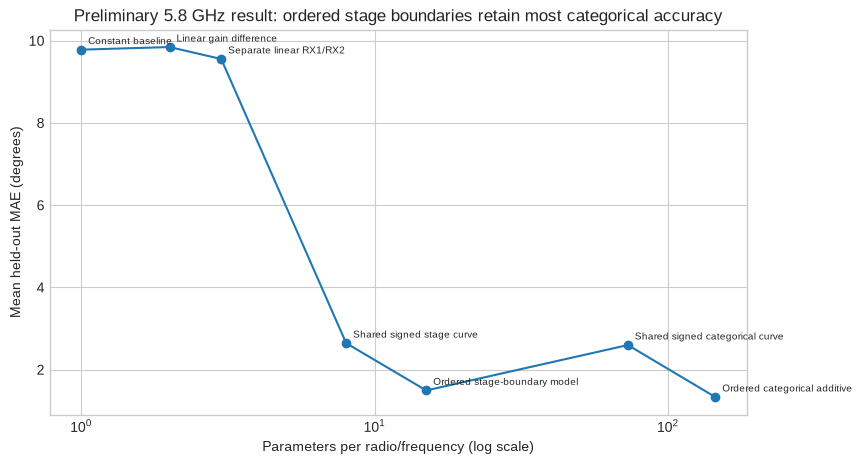

In [8]:
coarse_path = REPORTS / 'coarse_5ghz_20260727_dds_v1/comparative_analysis.json'
coarse = json.loads(coarse_path.read_text())
stage_rows = []
for serial, radio in coarse['radios'].items():
    for frequency_hz, result in radio['frequency_results'].items():
        for model_id, values in result['random_cell_five_fold']['models'].items():
            stage_rows.append({
                'serial': serial[-8:],
                'frequency_mhz': int(frequency_hz) / 1e6,
                'model_id': model_id,
                'label': values['label'],
                'parameters_per_radio_frequency': values['nominal_parameters'],
                'mae_deg': values['circular_mae_deg'],
                'p95_deg': values['circular_p95_deg'],
            })
stage_df = pd.DataFrame(stage_rows)
stage_summary = (stage_df.groupby(['label', 'parameters_per_radio_frequency'], as_index=False)
                 .agg(mean_mae_deg=('mae_deg', 'mean'), worst_mae_deg=('mae_deg', 'max'),
                      mean_p95_deg=('p95_deg', 'mean'))
                 .sort_values('parameters_per_radio_frequency'))
display(stage_summary.round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(stage_summary.parameters_per_radio_frequency, stage_summary.mean_mae_deg, 'o-')
for _, row in stage_summary.iterrows():
    ax.annotate(row.label, (row.parameters_per_radio_frequency, row.mean_mae_deg),
                xytext=(5, 4), textcoords='offset points', fontsize=7)
ax.set_xscale('log')
ax.set(xlabel='Parameters per radio/frequency (log scale)', ylabel='Mean held-out MAE (degrees)',
       title='Preliminary 5.8 GHz result: ordered stage boundaries retain most categorical accuracy')
plt.show()

## 6. Why a smooth RF-only model is insufficient

The RF path contributes a frequency-linear phase term $-2\pi f\,\Delta\tau$, but the Pluto/AD936x setup adds discrete, frequency-table-dependent gain states and retune-dependent phase. Differential phase observes only RX1 minus RX2; it cannot identify either absolute branch delay. The following diagnostics quantify the staircase and low-rank structure of the fitted symmetric gain curves.

,value
maximum_absolute_deg,26.472736
median_absolute_deg,0.303721
n_steps,6678.000000
p90_absolute_deg,1.654995
p95_absolute_deg,4.189408
p99_absolute_deg,14.443869


,serial,frequency_mhz,gain_from_db,gain_to_db,step_deg
0,104000bac4950008230026001b440a003a,433.0,30,31,-26.473
1,1040007c4a94000211000b009186843ef2,433.0,30,31,-24.071
2,1040007c4a94000211000b009186843ef2,800.0,30,31,-19.860
3,1040007c4a94000211000b009186843ef2,3000.0,29,30,19.312
4,104000bac4950008230026001b440a003a,3000.0,29,30,19.036
5,104000bac4950008230026001b440a003a,3900.0,49,50,-18.880
6,104000bac4950008230026001b440a003a,2300.0,49,50,-18.858
7,1040007c4a94000211000b009186843ef2,3900.0,49,50,-18.709
8,1040007c4a94000211000b009186843ef2,2300.0,49,50,-18.667
9,1040007c4a94000211000b009186843ef2,5600.0,40,41,-18.374


,gain_table_scope,best_rank1_energy_fraction,best_rank2_energy_fraction,best_rank3_energy_fraction,forced_frequency_energy_fraction,forced_frequency_rms_deg,frequency_count
0,all,0.703,0.895,0.952,0.573,5.683,53.0
1,high,0.868,0.994,0.997,0.846,4.009,16.0
2,low,0.768,0.962,0.997,0.280,4.270,14.0
3,middle,0.873,0.992,0.996,0.793,4.224,23.0


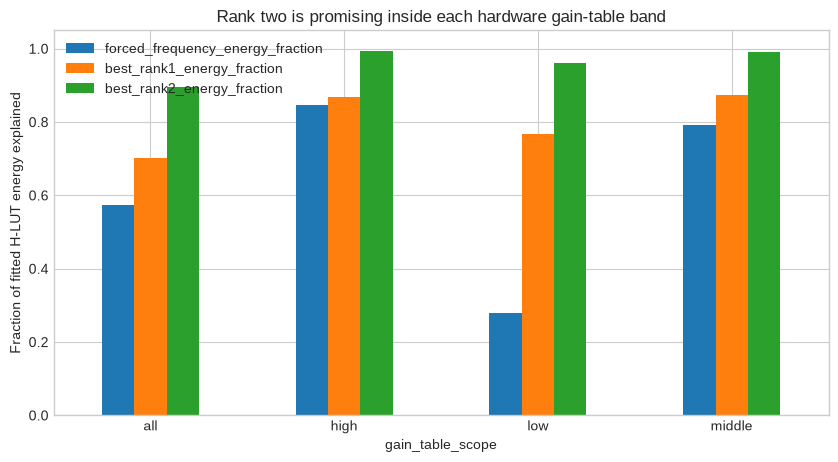

**Interpretation:** the median 1 dB change is small, but the tail contains 14–26° stage jumps. A linear gain coefficient is therefore physically wrong. Rank-two reconstruction explains 96–99% of fitted gain-curve energy within each AD936x table band, but that is descriptive coefficient reconstruction—not yet held-out phase-prediction evidence.

In [9]:
step_info = wide_doc['symmetric_gain_structure']
step_distribution = pd.Series(step_info['adjacent_one_db_step_distribution'], name='value')
largest_steps = pd.DataFrame(step_info['largest_steps'])
largest_steps['frequency_mhz'] = largest_steps.frequency_hz / 1e6
display(step_distribution.to_frame())
display(largest_steps[['serial', 'frequency_mhz', 'gain_from_db', 'gain_to_db', 'step_deg']]
        .head(12).round(3).reset_index(drop=True))

rank_summary = (pd.DataFrame(wide_doc['frequency_scaling_structure']['mean_across_radios']).T
                .rename_axis('gain_table_scope').reset_index())
display(rank_summary.round(3))

rank_plot = rank_summary.set_index('gain_table_scope')[
    ['forced_frequency_energy_fraction', 'best_rank1_energy_fraction', 'best_rank2_energy_fraction']
]
rank_plot.plot.bar(figsize=(10, 5))
plt.ylabel('Fraction of fitted H-LUT energy explained')
plt.title('Rank two is promising inside each hardware gain-table band')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.show()
display(Markdown(
    '**Interpretation:** the median 1 dB change is small, but the tail contains 14–26° stage jumps. '
    'A linear gain coefficient is therefore physically wrong. Rank-two reconstruction explains 96–99% '
    'of fitted gain-curve energy within each AD936x table band, but that is descriptive coefficient '
    'reconstruction—not yet held-out phase-prediction evidence.'
))

## 7. New-radio calibration cost

An unseen Pluto needs its own absolute phase anchor. Four-radio leave-one-radio-out results show that a single global or two-point delay anchor is inadequate across 12 LOs; one equal-gain anchor **at each operating frequency** is materially better. The anchors are excluded from scoring.

,strategy,calibration_values_per_radio,anchor_frequencies_hz,mae_deg,p95_deg,coverage_fraction
0,unadapted,0,NaN,14.171,51.411,1.0
1,fixed_one_value,1,2412000000,14.008,42.885,1.0
2,fixed_two_values,2,868000000;5866000000,10.996,37.430,1.0
3,one_value_per_frequency,12,NaN,3.385,11.274,1.0


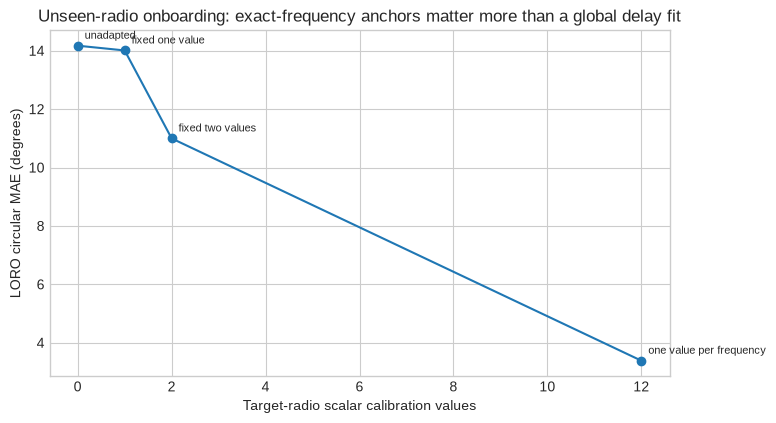

In [10]:
low_cost_path = REPORTS / 'four_radio_dense_20260728_v1/low_cost_metrics.csv'
low_cost = pd.read_csv(low_cost_path)
base_id = 'frequency_specific_additive_gain_universal'
fixed_strategies = ['unadapted', 'fixed_one_value', 'fixed_two_values', 'one_value_per_frequency']
onboarding = low_cost[(low_cost.model == base_id) & low_cost.strategy.isin(fixed_strategies)].copy()
display(onboarding[['strategy', 'calibration_values_per_radio', 'anchor_frequencies_hz',
                    'mae_deg', 'p95_deg', 'coverage_fraction']].round(3).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(onboarding.calibration_values_per_radio, onboarding.mae_deg, 'o-')
for _, row in onboarding.iterrows():
    ax.annotate(row.strategy.replace('_', ' '), (row.calibration_values_per_radio, row.mae_deg),
                xytext=(5, 5), textcoords='offset points', fontsize=8)
ax.set(xlabel='Target-radio scalar calibration values', ylabel='LORO circular MAE (degrees)',
       title='Unseen-radio onboarding: exact-frequency anchors matter more than a global delay fit')
plt.show()

## 8. Recommended training ladder

Use the same circular loss, quality-valid mask, and exact phase convention for every rung. Counts below use the wide experiment ($R=2$ radios, $F=53$ frequencies, $B=3$ gain-table bands, $G=64$ gains, and $S=7$ fixed stage features: six driver-derived boundaries plus the high-gain ramp). A reference gain fixes one LUT coefficient to zero.

| Rung | Formula | Fleet parameters | Status / purpose |
|---|---|---:|---|
| 0 | $C_r$ | 2 | Tested negative control; 14.81° LOEO MAE |
| 1 | $C_r+\beta_1g_1+\beta_2g_2$ | 6 | Tested negative control; linear gain is incompatible with stage jumps |
| 2 | $C_{r,f}+H_{b}(g_1)-H_b(g_2)$ | 127 shared / 148 radio-specific | **Next test:** fixed hardware-stage or small band LUT basis with exact-LO anchors |
| 3 | $C_{r,f}+A_b(g_1)+B_b(g_2)$ | 148 shared / 190 radio-specific | **Next test:** ordered branch-specific stage effects; motivated by the 15-parameter 5.8 GHz result |
| 4 | $C_{r,f}+(f/\mathrm{GHz})[H_{r,b}(g_1)-H_{r,b}(g_2)]$ | 484 | Tested compact choice; 2.496° off-axis MAE |
| 5 | $C_{r,f}+\sum_{k=1}^{2}s_{r,b,k}(f)[H_{r,b,k}(g_1)-H_{r,b,k}(g_2)]$ | about 1,074 | **Next test:** rank-two band residual; coefficient-energy evidence only so far |
| 6 | $C_{r,f}+H_{r,f}(g_1)-H_{r,f}(g_2)$ | 6,784 | Tested parsimonious precision default; 1.074° off-axis MAE |
| 7 | $C_{r,f}+A_{r,f}(g_1)+B_{r,f}(g_2)$ | 13,462 | Tested accuracy reference; 0.805° off-axis MAE |
| 8 | $L_{r,f,g_1,g_2}$ | 18,535 | Rejected: more parameters and slightly worse held-out error |

The exact count for rungs 2–3 depends on whether stage amplitudes are shared across radios; fit both with hierarchical shrinkage and report the effective as well as nominal degrees of freedom. Rung 5's count is $R[F+2F+2B(G-1)]$ for a radio-specific rank-two band model.

## 9. Selection rule and experimental gaps

Select the smallest rung whose **matched-mask** off-axis MAE is ≤1.5°, p95 is ≤5°, and coverage is 100% on its declared support. Use LOEO as a repeatability check, not as the sole generalization score. For unseen-radio claims, train on whole physical radios and allow only predeclared target anchors; for unseen-frequency claims, hold out contiguous LO neighborhoods as well as individual LOs.

Before production promotion, add grouped tests that the current reports cannot supply: reboot/RAM-reload session holdout, controlled temperature holdout, fixture/install holdout, and real receive/beamforming validation. RF-DC initialization and metadata/quality gates are part of the model contract. Fail closed for an unvalidated serial, exact LO, ordered gain pair, session anchor, clipping/coherence failure, or gain-change event.

In [11]:
# Machine-checked recommendation values: fail loudly if regenerated reports change the decision.
off_axis_by_id = off_axis.set_index('model_id')
assert off_axis_by_id.loc['frequency_specific_antisymmetric_gain_per_radio', 'mae_deg'] < 1.5
assert off_axis_by_id.loc['frequency_specific_antisymmetric_gain_per_radio', 'p95_deg'] < 5.0
assert off_axis_by_id.loc['frequency_specific_additive_gain_per_radio', 'mae_deg'] < off_axis_by_id.loc['frequency_specific_antisymmetric_gain_per_radio', 'mae_deg']
wide_by_id = wide.set_index('model_id')
assert wide_by_id.loc['frequency_specific_additive_gain_per_radio', 'parameters'] < wide_by_id.loc['full_cell_lut_per_radio', 'parameters']
assert wide.set_index('model_id').loc['branch_gain_delay_lut_per_radio', 'lofo_mae_deg'] > 10.0

display(Markdown("""### Final recommendation

1. **Precision default:** exact-serial, exact-frequency antisymmetric `H` LUT.
2. **When <1° matters:** independent RX1/RX2 exact-frequency LUT.
3. **When memory/calibration cost dominates:** gain-table-specific frequency-scaled symmetric LUT.
4. **Next experiment:** cross-band ordered hardware-stage model, then a rank-two residual only if needed.
5. **Never infer:** absolute branch delays, an unseen LO correction, or an unseen-radio intercept without new anchors.
"""))

### Final recommendation

1. **Precision default:** exact-serial, exact-frequency antisymmetric `H` LUT.
2. **When <1° matters:** independent RX1/RX2 exact-frequency LUT.
3. **When memory/calibration cost dominates:** gain-table-specific frequency-scaled symmetric LUT.
4. **Next experiment:** cross-band ordered hardware-stage model, then a rank-two residual only if needed.
5. **Never infer:** absolute branch delays, an unseen LO correction, or an unseen-radio intercept without new anchors.


## 10. Optional raw-data refit

Populate `RETRAIN_DATASETS` with one primary V7 store per physical serial when the gitignored artifacts are mounted. This invokes the repository's canonical trainer/evaluator rather than duplicating its circular fitting code in the notebook. It writes to a new artifact directory and leaves the committed evidence untouched.

In [12]:
RETRAIN_DATASETS: list[Path] = []  # Example: [REPO / 'artifacts/.../SERIAL/calibration.v7.zarr']
RETRAIN_CONFIG = REPO / 'spf/calibrations/dual_rx_gain_frequency/configs/wide_integer_gain_cross_band.yaml'
RETRAIN_OUTPUT = REPO / 'artifacts/dual_rx_gain_frequency/notebook_model_matrix'

if RETRAIN_DATASETS:
    missing = [path for path in RETRAIN_DATASETS if not path.exists()]
    if missing:
        raise FileNotFoundError(f'Missing V7 stores: {missing}')
    command = [
        sys.executable, '-m', 'spf.calibrations.dual_rx_gain_frequency', 'model-matrix',
        '--config', str(RETRAIN_CONFIG),
    ]
    for dataset in RETRAIN_DATASETS:
        command.extend(['--dataset', str(dataset)])
    command.extend(['--output-dir', str(RETRAIN_OUTPUT)])
    subprocess.run(command, cwd=REPO, check=True)
else:
    display(Markdown('Raw refit skipped: set `RETRAIN_DATASETS` after mounting the V7 artifacts.'))

Raw refit skipped: set `RETRAIN_DATASETS` after mounting the V7 artifacts.